<a href="https://colab.research.google.com/github/shrutiras/Single-Cell-perturbation-project/blob/main/Single_Cell_Perturbation_Project_Plan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#before starting plz first load the dataset
!pip install scanpy
import scanpy as sc
adata= sc.read_h5ad('/content/FrangiehIzar2021_protein.h5ad')
print(adata)
#data-set checks
# 1. Check the matrix
print(adata.X.shape)
print(adata.X.dtype)

# 2. Check protein labels
print(adata.var[['Target', 'Clone', 'Barcode']])

# 3. Check perturbation groups
print(adata.obs['perturbation'].value_counts().head(20))

# 4. Check whether RNA data are present
print(adata.layers.keys())
print(adata.uns.keys())
# Check whether the perturbation metadata
# includes gene-level information beyond its name.

print(adata.obs[['perturbation', 'perturbation_type',
                 'perturbation_type_2', 'sgRNA',
                 'guide_id', 'nperts', 'ngenes']].head(10))

# Check the number of unique perturbations.
print(adata.obs['perturbation'].nunique())

# Check the number of cells per perturbation.
print(adata.obs['perturbation'].value_counts().describe())
# Number of cells per perturbation
counts = adata.obs["perturbation"].value_counts()

# How many perturbations have at least 100 cells?
print("At least 100 cells:", (counts >= 100).sum())

# How many have at least 200 cells?
print("At least 200 cells:", (counts >= 200).sum())

# Check experimental conditions
print(adata.obs["perturbation_type_2"].value_counts())

# Check whether protein measurements are normalized
print(adata.X.min(), adata.X.max())
print(adata.obs.columns.tolist())
print(adata.obs.nunique())
print(adata.var_names.tolist())
print(type(adata.X), adata.X.shape, list(adata.layers.keys()))
print(adata.obs.groupby("perturbation")["guide_id"].nunique().describe())


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 121.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 85.7 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


AnnData object with n_obs × n_vars = 218331 × 24
    obs: 'library_preparation_protocol', 'perturbation_2', 'MOI', 'sgRNA', 'UMI_count', 'guide_id', 'umap_x', 'umap_y', 'perturbation', 'tissue_type', 'cancer', 'disease', 'perturbation_type', 'celltype', 'organism', 'perturbation_type_2', 'nperts', 'ngenes', 'ncounts', 'percent_mito', 'percent_ribo'
    var: 'Target', 'Clone', 'TotalSeq A#', 'Barcode', 'Isotype_control', 'ncounts', 'ncells'
    layers: None (.X)
(218331, 24)
float32
                                 Target      Clone          Barcode
protein                                                            
CD117                             CD117      104D2  AGACTAATAGCTGAC
CD119                             CD119    GIR-208  TGTGTATTCCCTTGT
CD140a                           CD140A       16A1  ATGCGCCGAGAATTA
CD140b                           CD140B       18A2  CAATGGTTCACTGCC
CD172a                           CD172a     15-414  CGTGTTTAACTTGAG
CD184                             CD1

In [ ]:
print("Shape:", adata.shape)
print("\nFeature names:")
print(adata.var_names.tolist())

print("\nPerturbation counts:")
print(adata.obs["perturbation"].value_counts().head(20))

print("\nCell types:")
print(adata.obs["celltype"].value_counts())

print("\nPerturbation types:")
print(adata.obs["perturbation_type"].value_counts(dropna=False))

print("\nGuide examples:")
print(adata.obs[["perturbation", "sgRNA", "guide_id"]].head(20))

print("\nValue range:", adata.X.min(), adata.X.max())
import numpy as np
import pandas as pd
from scipy import sparse

X = adata.X
values = X.data if sparse.issparse(X) else np.asarray(X).ravel()

print("Matrix type:", type(X))
print("Nonzero fraction:", np.mean(values != 0))
print("Value quantiles:", np.quantile(values, [0, .25, .5, .75, .9, .99, 1]))

print("\nPerturbation labels:", adata.obs["perturbation"].nunique())
print("Missing guide_id:", adata.obs["guide_id"].isna().sum())
print("Missing sgRNA:", adata.obs["sgRNA"].isna().sum())

print("\nExample multi-guide rows:")
multi = adata.obs["guide_id"].astype(str).str.contains(";")
print(adata.obs.loc[multi, ["perturbation", "sgRNA", "guide_id"]].head(10))

print("\nMetadata columns:")
print(adata.obs.columns.tolist())
print("\nFeature metadata:")
print(adata.var)

Shape: (218331, 24)

Feature names:
['CD117', 'CD119', 'CD140a', 'CD140b', 'CD172a', 'CD184', 'CD202b', 'CD274', 'CD29', 'CD309', 'CD44', 'CD47', 'CD49f', 'CD58', 'CD59', 'CD61', 'HLA_A', 'Rat_IgG2a', 'Mouse_IgG1', 'Mouse_IgG2a', 'Mouse_IgG2b', 'HLA_E', 'CD9', 'CD279']

Perturbation counts:
perturbation
control     57605
ACTA2        1458
B2M          1379
A2M          1331
AEBP1        1302
CD59         1238
CD274        1222
CTSD         1217
IFNGR2       1203
CSPG4        1195
CD44         1193
FGFR1        1182
CDH19        1175
CD58         1166
APOC2        1137
APOE         1127
C19orf48     1126
ATP1B1       1122
JAK2         1120
AGA          1116
Name: count, dtype: int64

Cell types:
celltype
melanocytes    218331
Name: count, dtype: int64

Perturbation types:
perturbation_type
CRISPR    218331
Name: count, dtype: int64

Guide examples:
          perturbation      sgRNA                       guide_id
cell_name                                                       
CELL_1    

In [ ]:
import numpy as np
from scipy import sparse

X = adata.X
values = X.data if sparse.issparse(X) else np.asarray(X).ravel()

print("Matrix type:", type(X))
print("Value quantiles:", np.quantile(values, [0, .25, .5, .75, .9, .99, 1]))
print("Nonzero fraction:", np.mean(values != 0))

print("\nAnnData file:")
print(adata.filename)

print("\nUnstructured metadata:")
print(adata.uns)

print("\nObservation metadata columns:")
print(adata.obs.columns.tolist())
import numpy as np
from scipy import sparse

X = adata.X
nonzero_per_protein = np.asarray((X != 0).sum(axis=0)).ravel()

print(dict(zip(adata.var_names, nonzero_per_protein)))

Matrix type: <class 'scipy.sparse._csc.csc_matrix'>
Value quantiles: [1.00000e+00 2.00000e+00 6.00000e+00 3.20000e+01 1.28000e+02 1.08000e+03
 8.76464e+05]
Nonzero fraction: 1.0

AnnData file:
None

Unstructured metadata:
OrderedDict()

Observation metadata columns:
['library_preparation_protocol', 'perturbation_2', 'MOI', 'sgRNA', 'UMI_count', 'guide_id', 'umap_x', 'umap_y', 'perturbation', 'tissue_type', 'cancer', 'disease', 'perturbation_type', 'celltype', 'organism', 'perturbation_type_2', 'nperts', 'ngenes', 'ncounts', 'percent_mito', 'percent_ribo']
{'CD117': np.int64(109844), 'CD119': np.int64(208751), 'CD140a': np.int64(62317), 'CD140b': np.int64(94374), 'CD172a': np.int64(159289), 'CD184': np.int64(133766), 'CD202b': np.int64(72538), 'CD274': np.int64(209732), 'CD29': np.int64(218326), 'CD309': np.int64(80143), 'CD44': np.int64(218327), 'CD47': np.int64(218238), 'CD49f': np.int64(215585), 'CD58': np.int64(208761), 'CD59': np.int64(212580), 'CD61': np.int64(114924), 'HLA_A': np

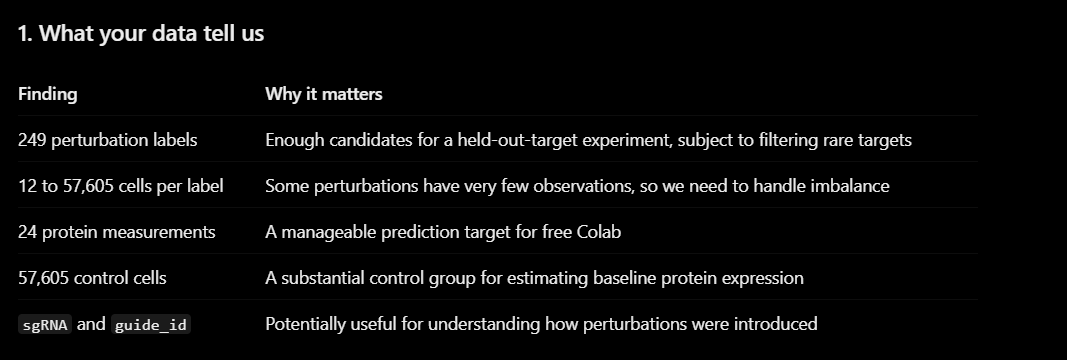